In [9]:
from google.colab import files
uploaded = files.upload()

Saving agri_dataset_with_challenge_columns.csv to agri_dataset_with_challenge_columns (1).csv


In [10]:
import pandas as pd

df = pd.read_csv(list(uploaded.keys())[0])
df.head()

,crop_ID,soil_type,Seedling_Stage,MOI,temp,humidity,result,Timestamp,Farm_ID,Rainfall,Irrigation_Status,Crop_Outcome
0,Wheat,Black Soil,Germination,1,25,80.0,1,2024-01-01,F1001,12.5,Irrigated,1
1,Wheat,Black Soil,Germination,2,26,77.0,1,2024-01-02,F1002,85.9,Irrigated,1
2,Wheat,Black Soil,Germination,3,27,74.0,1,2024-01-03,F1003,11.3,Irrigated,1
3,Wheat,Black Soil,Germination,4,28,71.0,1,2024-01-04,F1004,70.5,Irrigated,1
4,Wheat,Black Soil,Germination,5,29,68.0,1,2024-01-05,F1005,78.3,Irrigated,1


In [11]:
df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16283 entries, 0 to 16282
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   crop_ID            16283 non-null  object 
 1   soil_type          16283 non-null  object 
 2   Seedling_Stage     16283 non-null  object 
 3   MOI                16283 non-null  int64  
 4   temp               16283 non-null  int64  
 5   humidity           16283 non-null  float64
 6   result             16283 non-null  int64  
 7   Timestamp          16283 non-null  object 
 8   Farm_ID            16283 non-null  object 
 9   Rainfall           16283 non-null  float64
 10  Irrigation_Status  16283 non-null  object 
 11  Crop_Outcome       16283 non-null  int64  
dtypes: float64(2), int64(4), object(6)
memory usage: 1.5+ MB


In [13]:
df.describe()

,MOI,temp,humidity,result,Rainfall,Crop_Outcome
count,16283.000000,16283.000000,16283.000000,16283.000000,16283.000000,16283.000000
mean,43.781858,28.912547,63.316004,0.520236,46.109716,0.520236
std,27.198158,9.692754,22.634381,0.622436,33.965418,0.622436
min,1.000000,13.000000,15.000000,0.000000,0.200000,0.000000
25%,21.000000,21.000000,44.000000,0.000000,12.200000,0.000000
50%,41.000000,29.000000,69.000000,0.000000,43.200000,0.000000
75%,64.000000,37.000000,83.000000,1.000000,78.500000,1.000000
max,100.000000,46.000000,91.000000,2.000000,150.000000,2.000000


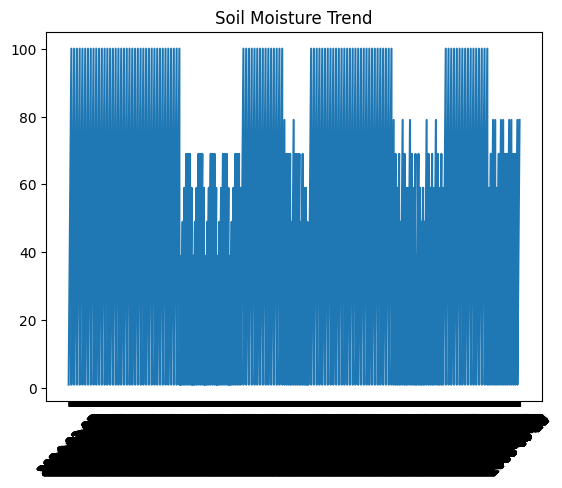

In [14]:
import matplotlib.pyplot as plt

plt.plot(df["Timestamp"], df["MOI"])
plt.title("Soil Moisture Trend")
plt.xticks(rotation=45)
plt.show()

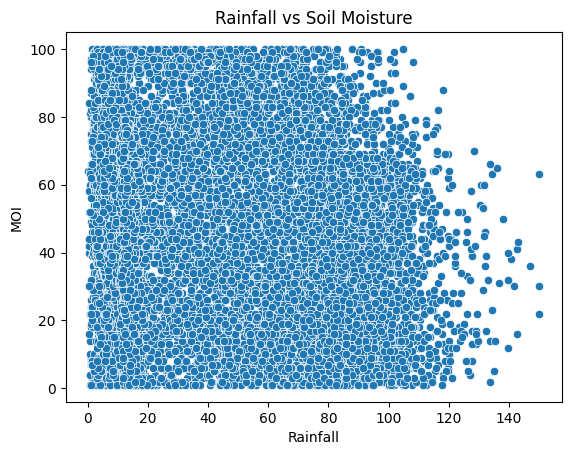

In [15]:
import seaborn as sns

sns.scatterplot(x="Rainfall", y="MOI", data=df)
plt.title("Rainfall vs Soil Moisture")
plt.show()

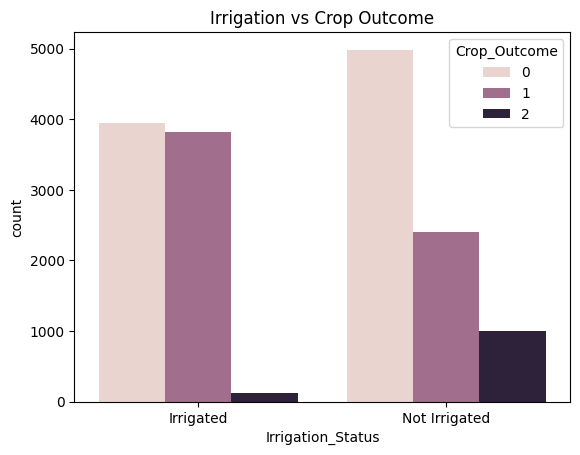

In [16]:
sns.countplot(x="Irrigation_Status", hue="Crop_Outcome", data=df)
plt.title("Irrigation vs Crop Outcome")
plt.show()

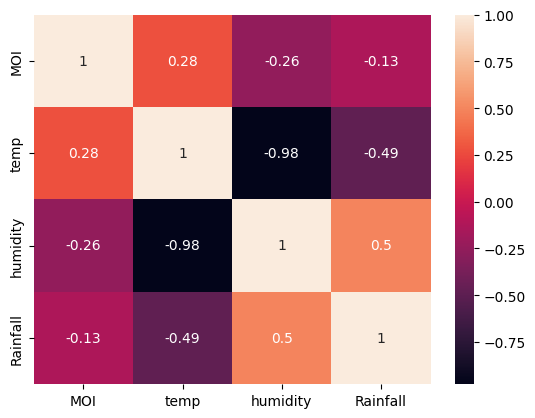

In [17]:
sns.heatmap(
    df[["MOI","temp","humidity","Rainfall"]].corr(),
    annot=True
)
plt.show()

In [19]:
stress = df[df["MOI"] < df["MOI"].median()]
print(stress.head())
print("Water stress records:", len(stress))

  crop_ID   soil_type  Seedling_Stage  MOI  temp  humidity  result  \
0   Wheat  Black Soil               2    1    25      80.0       1   
1   Wheat  Black Soil               2    2    26      77.0       1   
2   Wheat  Black Soil               2    3    27      74.0       1   
3   Wheat  Black Soil               2    4    28      71.0       1   
4   Wheat  Black Soil               2    5    29      68.0       1   

    Timestamp Farm_ID  Rainfall  Irrigation_Status  Crop_Outcome  
0  2024-01-01   F1001      12.5                  0             1  
1  2024-01-02   F1002      85.9                  0             1  
2  2024-01-03   F1003      11.3                  0             1  
3  2024-01-04   F1004      70.5                  0             1  
4  2024-01-05   F1005      78.3                  0             1  
Water stress records: 7981


In [20]:
unnecessary = df[
    (df["Irrigation_Status"] == "Yes") &
    (df["MOI"] > df["MOI"].median()) &
    (df["Rainfall"] > 0)
]

print("Potential unnecessary irrigation:", len(unnecessary))

Potential unnecessary irrigation: 0


In [18]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

le = LabelEncoder()

df["Seedling_Stage"] = le.fit_transform(df["Seedling_Stage"])
df["Irrigation_Status"] = le.fit_transform(df["Irrigation_Status"])

X = df[["MOI","temp","humidity","Rainfall","Seedling_Stage"]]
y = df["Irrigation_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8477126189745164
